In [1]:
from pathlib import Path
import sys


def _find_carl_project_root(start=Path.cwd()):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root from the notebook working directory.")


PROJECT_ROOT = _find_carl_project_root()
sys.path.insert(0, str(PROJECT_ROOT))


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data_dir = str(PROJECT_ROOT / "data" / "processed" / "TEP") + "/"
split_keys = ["Training", "Testing"]

In [4]:
df_dict = {}
for split_key in split_keys:
    file_name = f"TEP_{split_key}.parquet"
    df = pd.read_parquet(data_dir + file_name)
    df_dict[split_key] = df

In [5]:
id_cols = ["simulationRun", "sample"]
fault_number_col = "faultNumber"
all_columns = list(df_dict["Training"].columns)
feature_cols = [col for col in all_columns if col not in id_cols and col != fault_number_col]

In [6]:
for split_key in split_keys:
    df = df_dict[split_key]
    print(f"{split_key}:")
    display(df)

Training:


,faultNumber,simulationRun,sample,X1,X2,X3,X4,X5,X6,X7,...,X24,X25,X26,X27,X28,X29,X30,X31,X32,X33
0,0,1,1,-0.003138,0.223913,0.381853,-0.993955,-0.045139,0.214047,-0.070707,...,-0.363349,0.003193,0.736842,-0.113636,-0.059622,1.048563,0.382362,-0.091553,0.210959,0.165573
1,0,1,2,0.014000,-0.093478,0.903592,0.684801,-0.628472,0.795987,0.000000,...,-0.884676,-0.013752,-1.205795,-0.188920,0.057198,0.114718,-0.884388,-0.116066,0.349315,-0.466936
2,0,1,3,-0.003138,-0.073913,-0.586011,0.824698,-0.093750,-0.896321,0.121212,...,0.605055,0.005403,-0.013601,0.231534,0.090160,0.222745,0.052664,-0.103957,0.130137,1.217062
3,0,1,4,-0.017861,-0.052174,0.062382,1.126943,-0.500000,-0.919732,0.222222,...,-0.044234,0.019892,-0.852750,0.085227,0.096461,-0.004708,0.315051,-0.047844,0.738356,-0.015144
4,0,1,5,1.050929,0.332609,-0.223062,-0.077720,-0.045139,1.043478,0.010101,...,-0.499210,1.019892,-0.343584,-0.383523,-0.443044,0.957384,0.347460,-0.139988,0.552055,0.172640
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4999995,20,500,496,-0.393917,-0.182609,-0.890359,-0.019862,0.368056,0.478261,-0.202020,...,-0.480253,-0.317780,-0.140154,-2.127841,0.456132,0.139247,0.266750,-0.086237,-1.221918,-0.232206
4999996,20,500,497,0.398986,-0.354348,0.593573,0.064767,0.458333,1.113712,-0.030303,...,1.067930,0.421906,-0.755766,-2.775568,0.737276,-1.106789,0.313493,-0.051093,0.130137,0.313983
4999997,20,500,498,0.360126,-0.726087,1.187146,0.533679,0.788194,0.441472,0.010101,...,0.473934,0.460953,-0.871674,-2.880682,0.701406,0.712587,1.840760,-0.005316,0.271233,2.564361
4999998,20,500,499,0.632392,-0.173913,-0.187146,0.267703,1.565972,-0.190635,0.080808,...,-0.739336,0.524804,0.898876,-2.505682,0.072710,0.710109,0.342163,0.078559,-0.813699,-1.103988


Testing:


,faultNumber,simulationRun,sample,X1,X2,X3,X4,X5,X6,X7,...,X24,X25,X26,X27,X28,X29,X30,X31,X32,X33
0,0,1,1,0.028965,0.189130,-0.803403,1.425734,0.538194,0.451505,0.060606,...,0.821485,-0.028733,-0.939089,0.198864,0.044111,0.491328,0.444064,-0.153574,1.364384,-1.400303
1,0,1,2,0.044171,-0.467391,1.132325,0.582038,0.336806,0.829431,0.020202,...,-1.113744,-0.043959,-0.492017,0.278409,-0.049443,-0.356789,-0.464942,-0.093916,-0.754795,-1.037860
2,0,1,3,-0.050929,-0.447826,-0.024575,-0.492228,0.086806,-0.200669,-0.151515,...,0.041074,0.053045,-0.387936,-0.025568,0.007756,0.935828,-0.616080,-0.100709,0.324658,1.177688
3,0,1,4,0.024620,-0.769565,0.198488,-0.107081,0.336806,-0.026756,-0.111111,...,-0.180095,-0.022348,0.360733,-0.335227,0.040233,0.489346,0.473045,-0.112227,-0.443836,-0.502776
4,0,1,5,-0.793628,-0.171739,1.175803,-0.331606,-0.003472,0.214047,0.272727,...,-1.053712,-0.704568,0.350680,0.276989,-1.144935,0.050545,-0.577127,-0.085647,-0.020548,0.283695
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9599995,20,500,956,0.348298,1.215217,0.527410,-1.041451,-0.093750,0.210702,0.333333,...,0.644550,0.337426,0.455352,-2.143466,-1.196801,-0.735877,-0.322219,-1.525989,-0.394521,-1.147400
9599996,20,500,957,0.048516,1.310870,-0.274102,-1.379965,1.107639,-1.133779,0.101010,...,0.413902,0.111493,0.153164,-2.218750,0.424624,0.074331,-0.882206,-1.473125,1.026027,0.185260
9599997,20,500,958,0.027275,0.806522,0.538752,-0.826425,-0.843750,-0.528428,-0.030303,...,-0.398104,0.132859,-0.076286,-2.225852,0.308289,-0.527750,-0.276410,-1.380095,-0.775342,0.004038
9599998,20,500,959,0.976587,-0.476087,0.310019,-0.360967,-0.274306,-0.347826,0.000000,...,0.333333,1.013507,-0.093436,-2.690341,-0.137664,0.425173,-0.168588,-1.329592,-0.380822,-0.410904


In [7]:
for split_key in split_keys:
    df = df_dict[split_key]
    print(f"{split_key}:")
    print(f"Number of NaNs: {df.isna().sum().sum()}")

Training:
Number of NaNs: 0
Testing:
Number of NaNs: 0


In [8]:
for split_key in split_keys:
    df = df_dict[split_key]
    for col in id_cols + [fault_number_col]:
        series = df[col]
        print(series.value_counts())

simulationRun
500    10500
1      10500
2      10500
3      10500
484    10500
       ...  
9      10500
8      10500
7      10500
6      10500
5      10500
Name: count, Length: 500, dtype: int64
sample
500    10500
1      10500
2      10500
3      10500
484    10500
       ...  
9      10500
8      10500
7      10500
6      10500
5      10500
Name: count, Length: 500, dtype: int64
faultNumber
0     250000
1     250000
2     250000
3     250000
4     250000
5     250000
6     250000
7     250000
8     250000
9     250000
10    250000
11    250000
12    250000
13    250000
14    250000
15    250000
16    250000
17    250000
18    250000
19    250000
20    250000
Name: count, dtype: int64
simulationRun
500    20160
1      20160
2      20160
3      20160
484    20160
       ...  
9      20160
8      20160
7      20160
6      20160
5      20160
Name: count, Length: 500, dtype: int64
sample
944    10500
943    10500
942    10500
941    10500
940    10500
       ...  
5      10500
4      105

In [9]:
for split_key in split_keys:
    df = df_dict[split_key]
    for fault_list in [[0], range(1, 21)]:
        df_fault_filter = df[df["faultNumber"].isin(fault_list)]
        std = df_fault_filter[feature_cols].std()
        print(f"{split_key} - {fault_list}")
        print(std)

Training - [0]
X1     0.745196
X2     0.739269
X3     0.741312
X4     0.740254
X5     0.734324
X6     0.730814
X7     0.760161
X8     0.735449
X9     0.955425
X10    0.740512
X11    0.750263
X12    0.734948
X13    0.763675
X14    0.738407
X15    0.732513
X16    0.758092
X17    0.739599
X18    0.793883
X19    0.805136
X20    0.763809
X21    0.745960
X22    0.740804
X23    0.737427
X24    0.741964
X25    0.746008
X26    0.735544
X27    0.753063
X28    0.740064
X29    0.734704
X30    0.732722
X31    0.802280
X32    0.740846
X33    0.738858
dtype: float64
Training - range(1, 21)
X1      3.609423
X2      0.938465
X3      2.098995
X4      3.148662
X5      0.805567
X6      1.060912
X7      7.676146
X8      1.821269
X9      3.645445
X10     5.081711
X11     5.662567
X12     0.730951
X13     7.435977
X14     0.802430
X15     0.734745
X16     9.162575
X17     0.778314
X18     3.468141
X19     5.400884
X20     5.218109
X21     7.378838
X22     4.031167
X23     4.224958
X24     8.306623
X25     5.

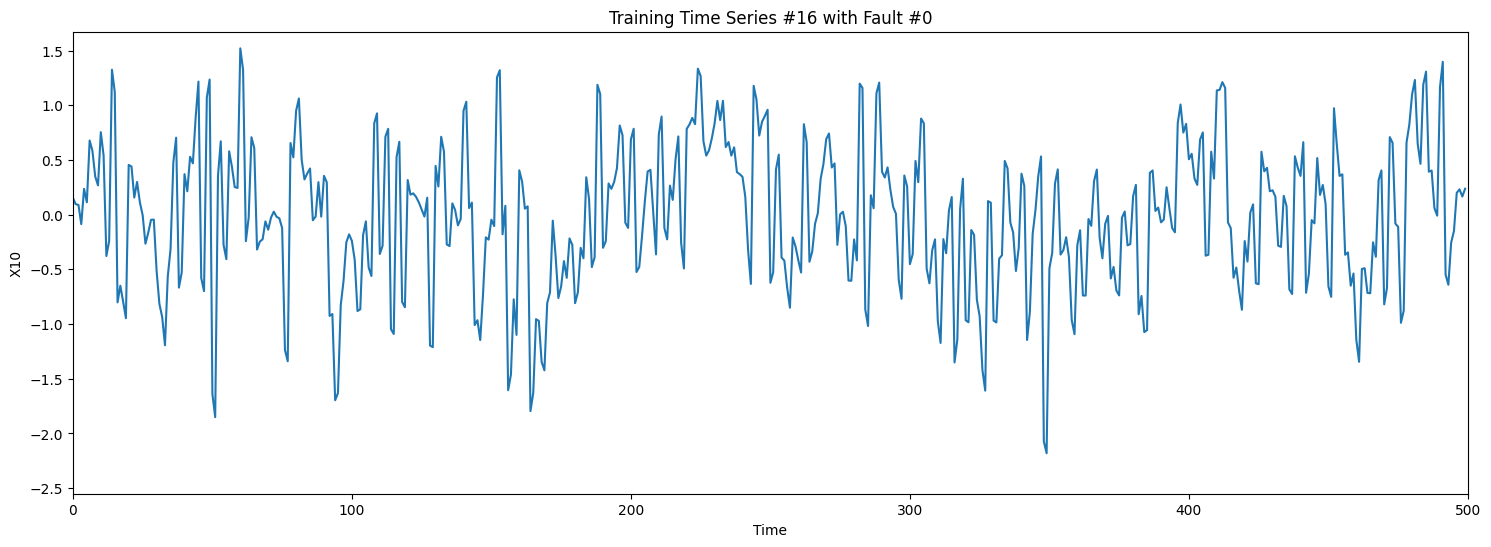

In [10]:
data_type = "Training" # "Training" or "Testing"
feature = "X10" # between "X1" and "X33"
fault_number = 0 # between 0 and 20
idx_time_series = 15 # number of the time series to show (between 0 and 499)

len_series = 500 if data_type == "Training" else 960
df = df_dict["Training"]
df = df[df["faultNumber"] == fault_number]
series = df[feature].reset_index(drop=True)
series = series[idx_time_series*len_series : (idx_time_series + 1)*len_series]
series = series.reset_index(drop=True)

series_min, series_max = series.min(), series.max()
series_diff = series_max - series_min
y_min, y_max = series_min - 0.1 * series_diff, series_max + 0.1 * series_max
plt.figure(figsize=(18, 6))
plt.plot(series)
plt.xlim([0, len_series])
plt.ylim([y_min, y_max])
plt.title(f"{data_type} Time Series #{idx_time_series + 1} with Fault #{fault_number}")
plt.xlabel("Time")
plt.ylabel(feature)
if fault_number != 0:
    anomaly_x = 20 if data_type == "Training" else 160
    plt.vlines(anomaly_x, ymin=y_min, ymax=y_max, label="Anomaly Introduced", colors="#DD4C30")
    plt.legend()
plt.show()